# Analysing Pharmaceutical Sales Data

This notebook analyses historical daily pharmaceutical sales with **Pandas** and **Matplotlib**. The goal is to compare sales across ATC drug categories and identify patterns over time.

## Project questions

1. What are the total sales quantities for each drug category?
2. Which available drug series have the highest total sales?
3. Which three drugs have the highest sales in January 2015, July 2016, and September 2017?
4. Which drug sold the greatest quantity in 2017?
5. Which drug category has the highest average daily sales?
6. Are respiratory drugs (`R03`) sold more during specific months?

> **Dataset note:** `salesdaily.csv` contains quantities aggregated by eight ATC codes. It does not include individual brand names, revenue, or transaction counts. Therefore, “drug” refers to an available ATC-code series in this analysis.

## 1. Setup and data loading

Import the required libraries, locate the source file, create the output image directory, and load the date column as a proper datetime value. The eight ATC columns are explicitly listed so that date-related columns are never mistaken for drugs.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
pd.options.display.float_format = '{:,.2f}'.format

In [2]:
# Works when launched from the project root or from notebooks/.
data_path = Path('data/salesdaily.csv')
if not data_path.exists():
    data_path = Path('../data/salesdaily.csv')

project_root = data_path.parent.parent.resolve()
image_dir = project_root / 'images' / 'sales_visualizations'
image_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path, parse_dates=['datum'])
drug_columns = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,2014-01-02,0.00,3.67,3.40,32.40,7.00,0.00,0.00,2.00,2014,1,248,Thursday
1,2014-01-03,8.00,4.00,4.40,50.60,16.00,0.00,20.00,4.00,2014,1,276,Friday
2,2014-01-04,2.00,1.00,6.50,61.85,10.00,0.00,9.00,1.00,2014,1,276,Saturday
3,2014-01-05,4.00,3.00,7.00,41.10,8.00,0.00,3.00,0.00,2014,1,276,Sunday
4,2014-01-06,5.00,1.00,4.50,21.70,16.00,2.00,6.00,2.00,2014,1,276,Monday


## 2. Data quality and preparation

Before answering the project questions, check the number of rows and columns, date range, missing values, duplicate rows, and negative sales quantities. Exact duplicates are removed defensively, the records are sorted by date, and reusable date features are created.

In [3]:
quality_report = pd.Series({
    'rows': len(df),
    'columns': df.shape[1],
    'missing_values': int(df.isna().sum().sum()),
    'duplicate_rows': int(df.duplicated().sum()),
    'negative_sales_values': int((df[drug_columns] < 0).sum().sum()),
    'start_date': df['datum'].min().date(),
    'end_date': df['datum'].max().date(),
}, name='value')
quality_report.to_frame()

,value
rows,2106
columns,13
missing_values,0
duplicate_rows,0
negative_sales_values,0
start_date,2014-01-02
end_date,2019-10-08


In [4]:
# Remove exact duplicates defensively, then derive consistent date features.
df = df.drop_duplicates().sort_values('datum').reset_index(drop=True)
df = df.assign(
    year=df['datum'].dt.year,
    month=df['datum'].dt.month,
    month_name=df['datum'].dt.month_name(),
    weekday=df['datum'].dt.day_name(),
)
df[drug_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
M01AB,"2,106.00",5.03,2.74,0.00,3.00,4.99,6.67,17.34
M01AE,"2,106.00",3.90,2.13,0.00,2.34,3.67,5.14,14.46
N02BA,"2,106.00",3.88,2.38,0.00,2.00,3.50,5.20,16.00
N02BE,"2,106.00",29.92,15.59,0.00,19.00,26.90,38.30,161.00
N05B,"2,106.00",8.85,5.61,0.00,5.00,8.00,12.00,54.83
N05C,"2,106.00",0.59,1.09,0.00,0.00,0.00,1.00,9.00
R03,"2,106.00",5.51,6.43,0.00,1.00,4.00,8.00,45.00
R06,"2,106.00",2.90,2.42,0.00,1.00,2.00,4.00,15.00


### Data quality finding

The dataset contains **2,106 daily records** from **2 January 2014 to 8 October 2019**. No missing values, duplicate rows, or negative sales quantities were found, so the data is suitable for the following analysis.

## 3. Analysis

### Question 1 — What are the total sales quantities for each drug category?

**Method:** Sum every daily value in each of the eight ATC columns, then sort the totals from highest to lowest.

In [5]:
total_sales = df[drug_columns].sum().sort_values(ascending=False)
total_sales.to_frame('total_quantity')

,total_quantity
N02BE,"63,005.40"
N05B,"18,645.74"
R03,"11,608.82"
M01AB,"10,600.94"
M01AE,"8,204.62"
N02BA,"8,172.21"
R06,"6,107.82"
N05C,"1,249.96"


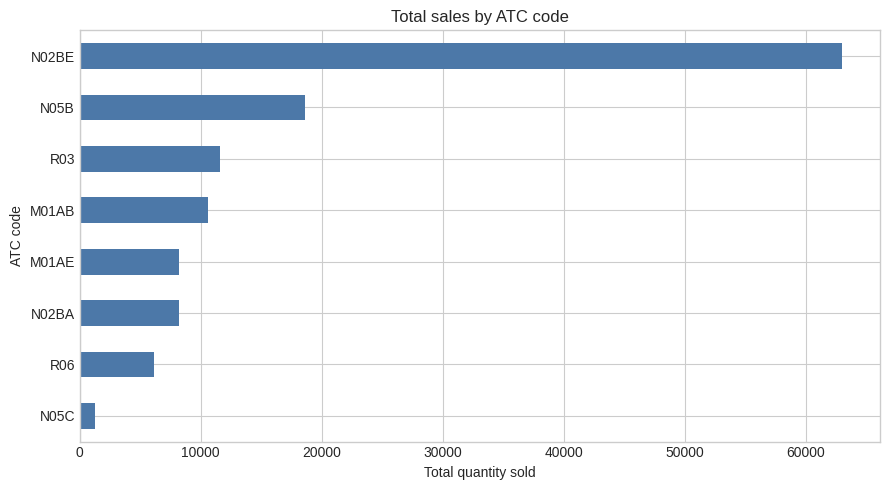

In [6]:
ax = total_sales.sort_values().plot(
    kind='barh', figsize=(9, 5), color='#4C78A8', title='Total sales by ATC code'
)
ax.set_xlabel('Total quantity sold')
ax.set_ylabel('ATC code')
plt.tight_layout()
ax.figure.savefig(image_dir / 'total_sales_by_atc_code.png', dpi=150, bbox_inches='tight')
plt.show()

**Finding:** `N02BE` has the highest overall sales at **63,005.40 units**. It is followed by `N05B` (**18,645.74**) and `R03` (**11,608.82**). `N05C` has the lowest total at **1,249.96 units**.

### Question 2 — Which individual drugs have the highest total sales?

The source data does not provide individual brand names. The most detailed valid comparison is therefore a ranking of the eight ATC-code series using the totals calculated above.

In [7]:
drug_ranking = total_sales.rename_axis('drug_code').reset_index(name='total_quantity')
drug_ranking.index = drug_ranking.index + 1
drug_ranking.index.name = 'rank'
drug_ranking

,drug_code,total_quantity
rank,,
1,N02BE,"63,005.40"
2,N05B,"18,645.74"
3,R03,"11,608.82"
4,M01AB,"10,600.94"
5,M01AE,"8,204.62"
6,N02BA,"8,172.21"
7,R06,"6,107.82"
8,N05C,"1,249.96"


**Finding:** The ranking confirms that `N02BE` is the leading series by a large margin, followed by `N05B` and `R03`.

### Question 3 — Which three drugs have the highest sales in the selected months?

**Method:** Filter the daily observations for January 2015, July 2016, and September 2017; sum each ATC series within each period; and select the three largest totals.

In [8]:
target_months = {
    'January 2015': (2015, 1),
    'July 2016': (2016, 7),
    'September 2017': (2017, 9),
}

top_three_rows = []
for period, (year, month) in target_months.items():
    period_totals = df.loc[
        (df['year'] == year) & (df['month'] == month), drug_columns
    ].sum().nlargest(3)
    for rank, (drug, quantity) in enumerate(period_totals.items(), start=1):
        top_three_rows.append({
            'period': period, 'rank': rank, 'drug_code': drug, 'quantity': quantity
        })

top_three = pd.DataFrame(top_three_rows)
top_three

,period,rank,drug_code,quantity
0,January 2015,1,N02BE,"1,044.24"
1,January 2015,2,N05B,463.00
2,January 2015,3,R03,177.25
3,July 2016,1,N02BE,652.36
4,July 2016,2,N05B,240.00
5,July 2016,3,M01AB,194.53
6,September 2017,1,N02BE,863.75
7,September 2017,2,N05B,223.00
8,September 2017,3,R03,139.00


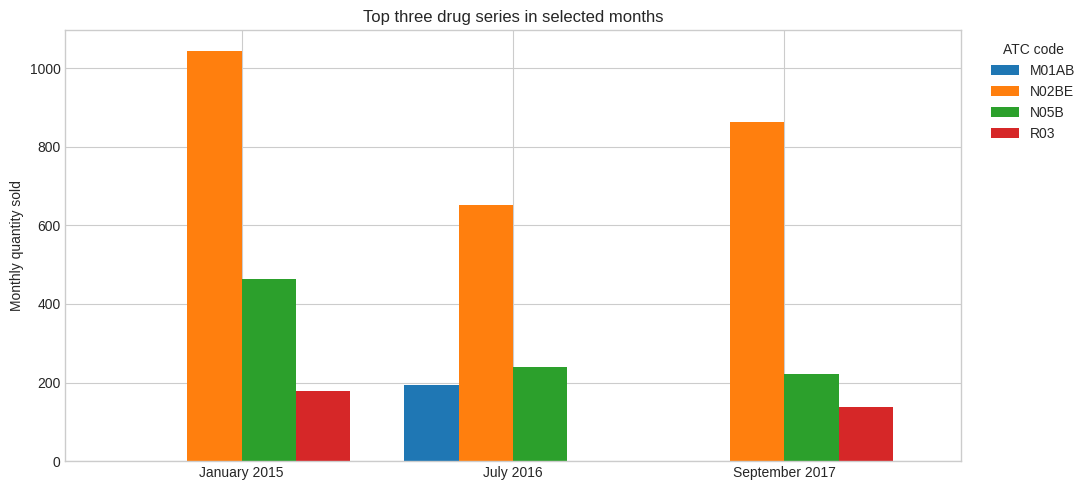

In [9]:
pivot_top_three = top_three.pivot(index='period', columns='drug_code', values='quantity').fillna(0)
pivot_top_three = pivot_top_three.reindex(target_months.keys())
ax = pivot_top_three.plot(kind='bar', figsize=(11, 5), width=0.8)
ax.set_title('Top three drug series in selected months')
ax.set_xlabel('')
ax.set_ylabel('Monthly quantity sold')
ax.tick_params(axis='x', rotation=0)
plt.legend(title='ATC code', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
ax.figure.savefig(image_dir / 'top_three_drugs_selected_months.png', dpi=150, bbox_inches='tight')
plt.show()

**Finding:**

| Period | 1st | 2nd | 3rd |
| --- | --- | --- | --- |
| January 2015 | `N02BE` | `N05B` | `R03` |
| July 2016 | `N02BE` | `N05B` | `M01AB` |
| September 2017 | `N02BE` | `N05B` | `R03` |

`N02BE` and `N05B` consistently occupy the first two positions in all three selected months.

### Question 4 — Which drug sold the most in 2017?

**Method:** Filter records to 2017 and compare the summed quantities. The phrase “sold the most often” is interpreted as the greatest quantity sold because transaction-level frequencies are not available.

In [10]:
sales_2017 = df.loc[df['year'] == 2017, drug_columns].sum().sort_values(ascending=False)
winner_2017 = sales_2017.index[0]
print(f'{winner_2017} sold the most in 2017: {sales_2017.iloc[0]:,.2f} units.')
sales_2017.to_frame('quantity_2017')

N02BE sold the most in 2017: 9,258.80 units.


,quantity_2017
N02BE,"9,258.80"
N05B,"2,555.54"
R03,"1,893.61"
M01AB,"1,846.62"
M01AE,"1,387.30"
N02BA,"1,288.30"
R06,988.86
N05C,180.33


**Finding:** `N02BE` sold the greatest quantity in 2017, with **9,258.80 units**.

### Question 5 — Which drug category has the highest average daily sales?

**Method:** Calculate the arithmetic mean of the daily quantity for every ATC series across the full observation period.

In [11]:
average_daily_sales = df[drug_columns].mean().sort_values(ascending=False)
print(
    f'{average_daily_sales.index[0]} has the highest average daily sales: '
    f'{average_daily_sales.iloc[0]:,.2f} units per day.'
)
average_daily_sales.to_frame('average_daily_quantity')

N02BE has the highest average daily sales: 29.92 units per day.


,average_daily_quantity
N02BE,29.92
N05B,8.85
R03,5.51
M01AB,5.03
M01AE,3.90
N02BA,3.88
R06,2.90
N05C,0.59


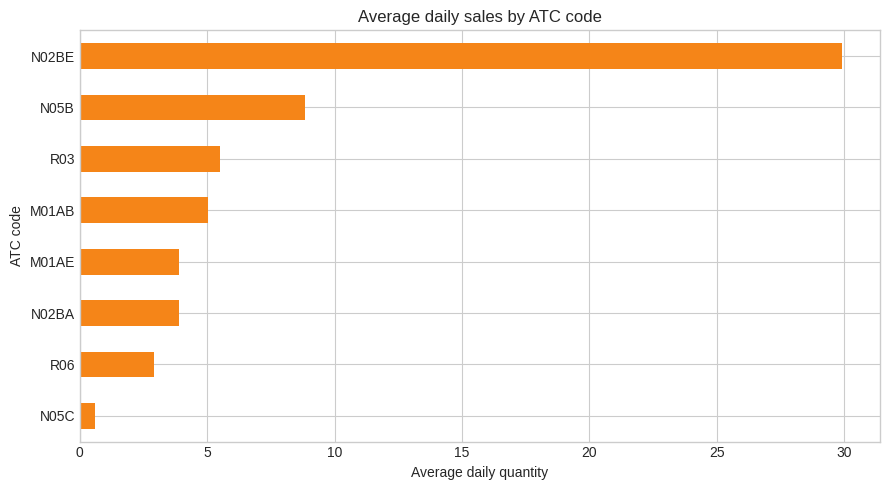

In [12]:
ax = average_daily_sales.sort_values().plot(
    kind='barh', figsize=(9, 5), color='#F58518', title='Average daily sales by ATC code'
)
ax.set_xlabel('Average daily quantity')
ax.set_ylabel('ATC code')
plt.tight_layout()
ax.figure.savefig(image_dir / 'average_daily_sales_by_atc_code.png', dpi=150, bbox_inches='tight')
plt.show()

**Finding:** `N02BE` has the highest average daily sales at **29.92 units per day**.

### Question 6 — Are respiratory drugs (`R03`) sold more during specific months?

**Method:** Group all `R03` observations by calendar month and compare average daily sales. The daily average is preferred to raw monthly totals because months have different lengths and the first and last years are incomplete.

In [13]:
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]
r03_by_month = (
    df.groupby('month_name')['R03']
      .agg(average_daily_sales='mean', total_sales='sum', observed_days='size')
      .reindex(month_order)
)
r03_by_month.sort_values('average_daily_sales', ascending=False)

,average_daily_sales,total_sales,observed_days
month_name,,,
December,7.92,"1,227.00",155
October,7.21,"1,175.00",163
February,6.90,"1,165.58",169
January,6.84,"1,264.66",185
March,6.29,"1,170.00",186
November,6.23,934.00,150
April,5.77,"1,038.88",180
May,5.01,931.29,186
September,4.40,792.42,180


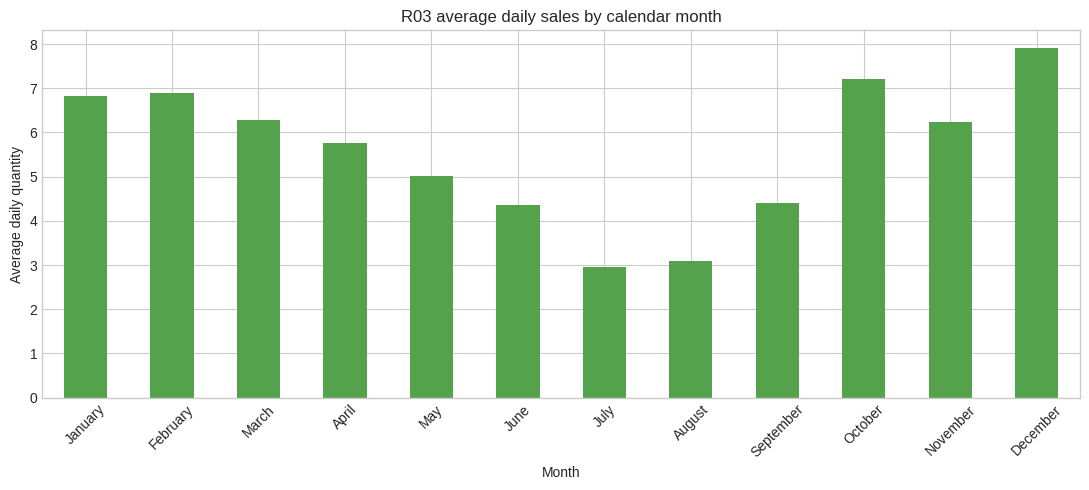

In [14]:
ax = r03_by_month['average_daily_sales'].plot(
    kind='bar', figsize=(11, 5), color='#54A24B', title='R03 average daily sales by calendar month'
)
ax.set_xlabel('Month')
ax.set_ylabel('Average daily quantity')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
ax.figure.savefig(image_dir / 'r03_average_daily_sales_by_month.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
peak_month = r03_by_month['average_daily_sales'].idxmax()
peak_value = r03_by_month.loc[peak_month, 'average_daily_sales']
lowest_month = r03_by_month['average_daily_sales'].idxmin()
lowest_value = r03_by_month.loc[lowest_month, 'average_daily_sales']
print(
    f'Yes. R03 sales show a seasonal pattern. {peak_month} has the highest average '
    f'({peak_value:,.2f} units/day), while {lowest_month} has the lowest '
    f'({lowest_value:,.2f} units/day).'
)

Yes. R03 sales show a seasonal pattern. December has the highest average (7.92 units/day), while July has the lowest (2.96 units/day).


**Finding:** Yes. `R03` shows a seasonal pattern. Average daily sales are highest in **December (7.92 units/day)** and lowest in **July (2.96 units/day)**. Sales are generally stronger from October through March and weaker during the middle of the year.

## 4. Conclusion

- `N02BE` is the dominant ATC series in total sales, selected-month rankings, 2017 sales, and average daily sales.
- `N05B` consistently ranks second in the three requested monthly comparisons.
- Respiratory drug sales (`R03`) display seasonality, with stronger average daily sales toward the end of the year and weaker sales in summer.

All tables, conclusions, and PNG charts are generated directly from `salesdaily.csv`. Running the notebook from top to bottom reproduces the complete analysis and saves the charts in `images/sales_visualizations/`.